# SPACEc: Preprocessing - Signal Preprocessing

In [1]:
# import spacec first
import spacec as sp

# import standard packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display  # explicit display() for figures shown mid-loop
# silencing warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Apply a larger, presentation-friendly style to all plots in this notebook.
sp.pl.set_style(sp.pl.SPACEcStyle.presentation())


In [ ]:
# Specify the path to the data
data_path = "path/to/example_data/raw/"
output_dir = "path/to/output/"
os.makedirs(output_dir, exist_ok=True)

In [4]:
#Read and concatenate the csv files (outputs from the cell segmentation algorithms) and add relevant metadata
df_seg = sp.pp.read_segdf(
    segfile_list = [ # list of segmented files
        output_dir + "tonsil1_features.csv",
        output_dir + "tonsil2_features.csv"
    ],
    seg_method = 'cellpose',
    region_list =["reg001", "reg002"],
    meta_list = ["tonsil", "tonsillitis"] # relevant metadata (e.g. condition). In case multiple metadata columns are needed, pass a dict with column names instead:
    # meta_list = {"condition": ["naive", "exposed", "naive", "exposed"], "time_point": ["day_0", "day_0", "day_14", "day_14"]}
)

#Get the shape of the data
print(df_seg.shape)

#See what it looks like
df_seg.head()

(51051, 72)


,y,x,area,eccentricity,perimeter,convex_area,axis_major_length,axis_minor_length,DAPI,FoxP3,...,CD45,CollagenIV,PD-L1,Arginase-1,GATA3,region_num,unique_region,condition,unique_cell_id,label
label,,,,,,,,,,,,,,,,,,,,,
1,166.227799,1532.957529,259.0,0.678429,60.384776,273.0,21.388458,15.713377,118.714286,0.189189,...,16.922780,4.571429,6.610039,2.486486,8.888031,0,reg001,tonsil,reg001_1,1
2,163.765217,1463.404348,230.0,0.786382,58.284271,247.0,21.860191,13.503920,66.665217,0.100000,...,13.682609,3.269565,4.878261,2.578261,6.121739,0,reg001,tonsil,reg001_2,2
3,162.546296,1486.888889,108.0,0.861229,41.112698,117.0,16.638924,8.456180,57.203704,0.194444,...,10.712963,2.796296,4.888889,2.592593,4.694444,0,reg001,tonsil,reg001_3,3
4,164.730942,1519.340807,223.0,0.552731,58.213203,243.0,19.164468,15.970902,118.520179,0.484305,...,10.860987,4.816143,6.695067,2.488789,9.708520,0,reg001,tonsil,reg001_4,4
5,168.369775,1426.536977,311.0,0.704341,71.112698,340.0,24.343966,17.280855,116.778135,0.192926,...,12.729904,4.581994,6.614148,2.636656,8.971061,0,reg001,tonsil,reg001_5,5


## Compensate fluorescence spillover (optional)

In densely packed tissue, fluorescent signal can "bleed" from a cell into its touching neighbors, inflating a cell's apparent marker intensity with signal that actually belongs next door. `sp.pp.compensate_cell_matrix` corrects for this using each region's raw segmentation mask and images. It must run here, on raw intensities right after `read_segdf` and before any filtering or normalization -- compensation is not meaningful on already-normalized values, since z-scoring/ArcSin etc. would need to be redone afterwards anyway.

Masks and images are loaded by path (`sp.hf.hf_load_masks` / `sp.hf.hf_load_image_dict`) rather than by unpickling a saved `seg_output` dict, and compensation runs one region at a time via `region=...`, since mask labels are only unique *within* a region (that's also why `df_seg` -- the concatenated, multi-region table -- must be scoped with `region=` rather than compensated all at once).

**NOTE:** For a closer look at what this step actually changes -- before/after QC plots, and guidance on when it helps vs. when it doesn't -- see [03.2_preprocessing_spillover_compensation.ipynb](03.2_preprocessing_spillover_compensation.ipynb). This section runs the same step directly with `overwrite=True`, so `df_seg`'s existing marker columns become the compensated values in place, rather than adding separate `_compensated` columns.

**NOTE:** Compensation runs on the CPU and its cost scales with the number of cells rather than its square -- a cell only touches a handful of neighbors, so the adjacency matrix is stored sparsely and solved directly. A 120,000-cell region takes a few seconds and about 10 MB, so there is no need to tile large regions.

This step is optional -- skip this section (and go straight to "Filter cells by DAPI intensity and area" below) if your panel has little spillover or you're already satisfied with raw intensities.

In [5]:
import gc

# One multichannel tif + mask per region, matching the file_name/output_fname
# used for each region's cell_segmentation(save_mask=True) call in 02_cell_segmentation.
region_to_image_file = {"reg001": "reg001_X01_Y01_Z01.tif", "reg002": "reg002_X01_Y01_Z01.tif"}
region_to_output_fname = {"reg001": "tonsil1", "reg002": "tonsil2"}

for region, output_fname in region_to_output_fname.items():
    image_dict = sp.hf.hf_load_image_dict(
        file_name = output_dir + region_to_image_file[region], # the multichannel tif segmented in 02_cell_segmentation
        channel_file = data_path + 'channelnames.txt',
        input_format = 'Multichannel',
        nuclei_channel = 'DAPI',
    )
    mask = sp.hf.hf_load_masks(
        {region: output_dir + f'{output_fname}_mask.tif'} # written by cell_segmentation(save_mask=True) in 02_cell_segmentation
    )[region]

    df_seg = sp.pp.compensate_cell_matrix(
        df_seg,
        image_dict = image_dict, # this region's channel images, loaded by path
        masks = mask, # this region's raw label mask, loaded by path
        region = region, # compensate only this region's rows (mask labels are unique only within a region)
        overwrite = True, # replace df_seg's raw marker columns in place with compensated values
    )

    del image_dict, mask # free this region's images before loading the next region
    gc.collect()

df_seg.shape

--- Loading Image Data (Format: Multichannel) ---
Loaded image shape: (59, 3122, 2866)
Formatting Multichannel image (59 channels)...
Formatted 59 Multichannel channels.
Image dictionary created with 59 channels.
This function uses code from Lee, M.Y., Bedia, J.S., Bhate, S.S. et al. CellSeg: a robust, pre-trained nucleus segmentation and pixel quantification software for highly multiplexed fluorescence images. BMC Bioinformatics 23, 46 (2022) please consider citing the original work.
--- Loading Image Data (Format: Multichannel) ---
Loaded image shape: (59, 2546, 2660)
Formatting Multichannel image (59 channels)...
Formatted 59 Multichannel channels.
Image dictionary created with 59 channels.
This function uses code from Lee, M.Y., Bedia, J.S., Bhate, S.S. et al. CellSeg: a robust, pre-trained nucleus segmentation and pixel quantification software for highly multiplexed fluorescence images. BMC Bioinformatics 23, 46 (2022) please consider citing the original work.


(51051, 72)

## Filter cells by DAPI intensity and area

In [6]:
# print smallest X% of cells by area
area_cutoff = np.percentile(df_seg.area, 0.7)
area_cutoff

61.0

In [7]:
# print smallest X% of cells by DAPI intensity
nuc_stain_cutoff = np.percentile(df_seg.DAPI, 3)

# Looser 5%/99% thresholds to FLAG (not drop) borderline cells with regards to DAPI
# intensity, small and big cells. 
# These feed filter_data's *_flag_thres args below, which add
# non-destructive qc_flag_* columns for inspection at clustering time (see 04_clustering).
area_flag_cutoff = np.percentile(df_seg.area, 5)
area_upper_flag_cutoff = np.percentile(df_seg.area, 99)
nuc_flag_cutoff = np.percentile(df_seg.DAPI, 5)
area_flag_cutoff, area_upper_flag_cutoff, nuc_flag_cutoff


(94.0, 459.0, 14.500365724231965)


Filter summary
──────────────────────────────────────────────
  Total cells          : 51,051
  Kept                 : 49,189  (96.4 %)
  Removed (low DAPI       ):  1,499  (2.9 %)
  Removed (small area     ):    330  (0.6 %)
  Removed (small & low DAPI):     33  (0.1 %)
──────────────────────────────────────────────
  Flagged (low DAPI    ):  1,003  (2.0 % of kept)
  Flagged (small area  ):  2,102  (4.3 % of kept)
  Flagged (large area  ):    501  (1.0 % of kept)
  Flagged (any flag    ):  3,488  (7.1 % of kept)
──────────────────────────────────────────────


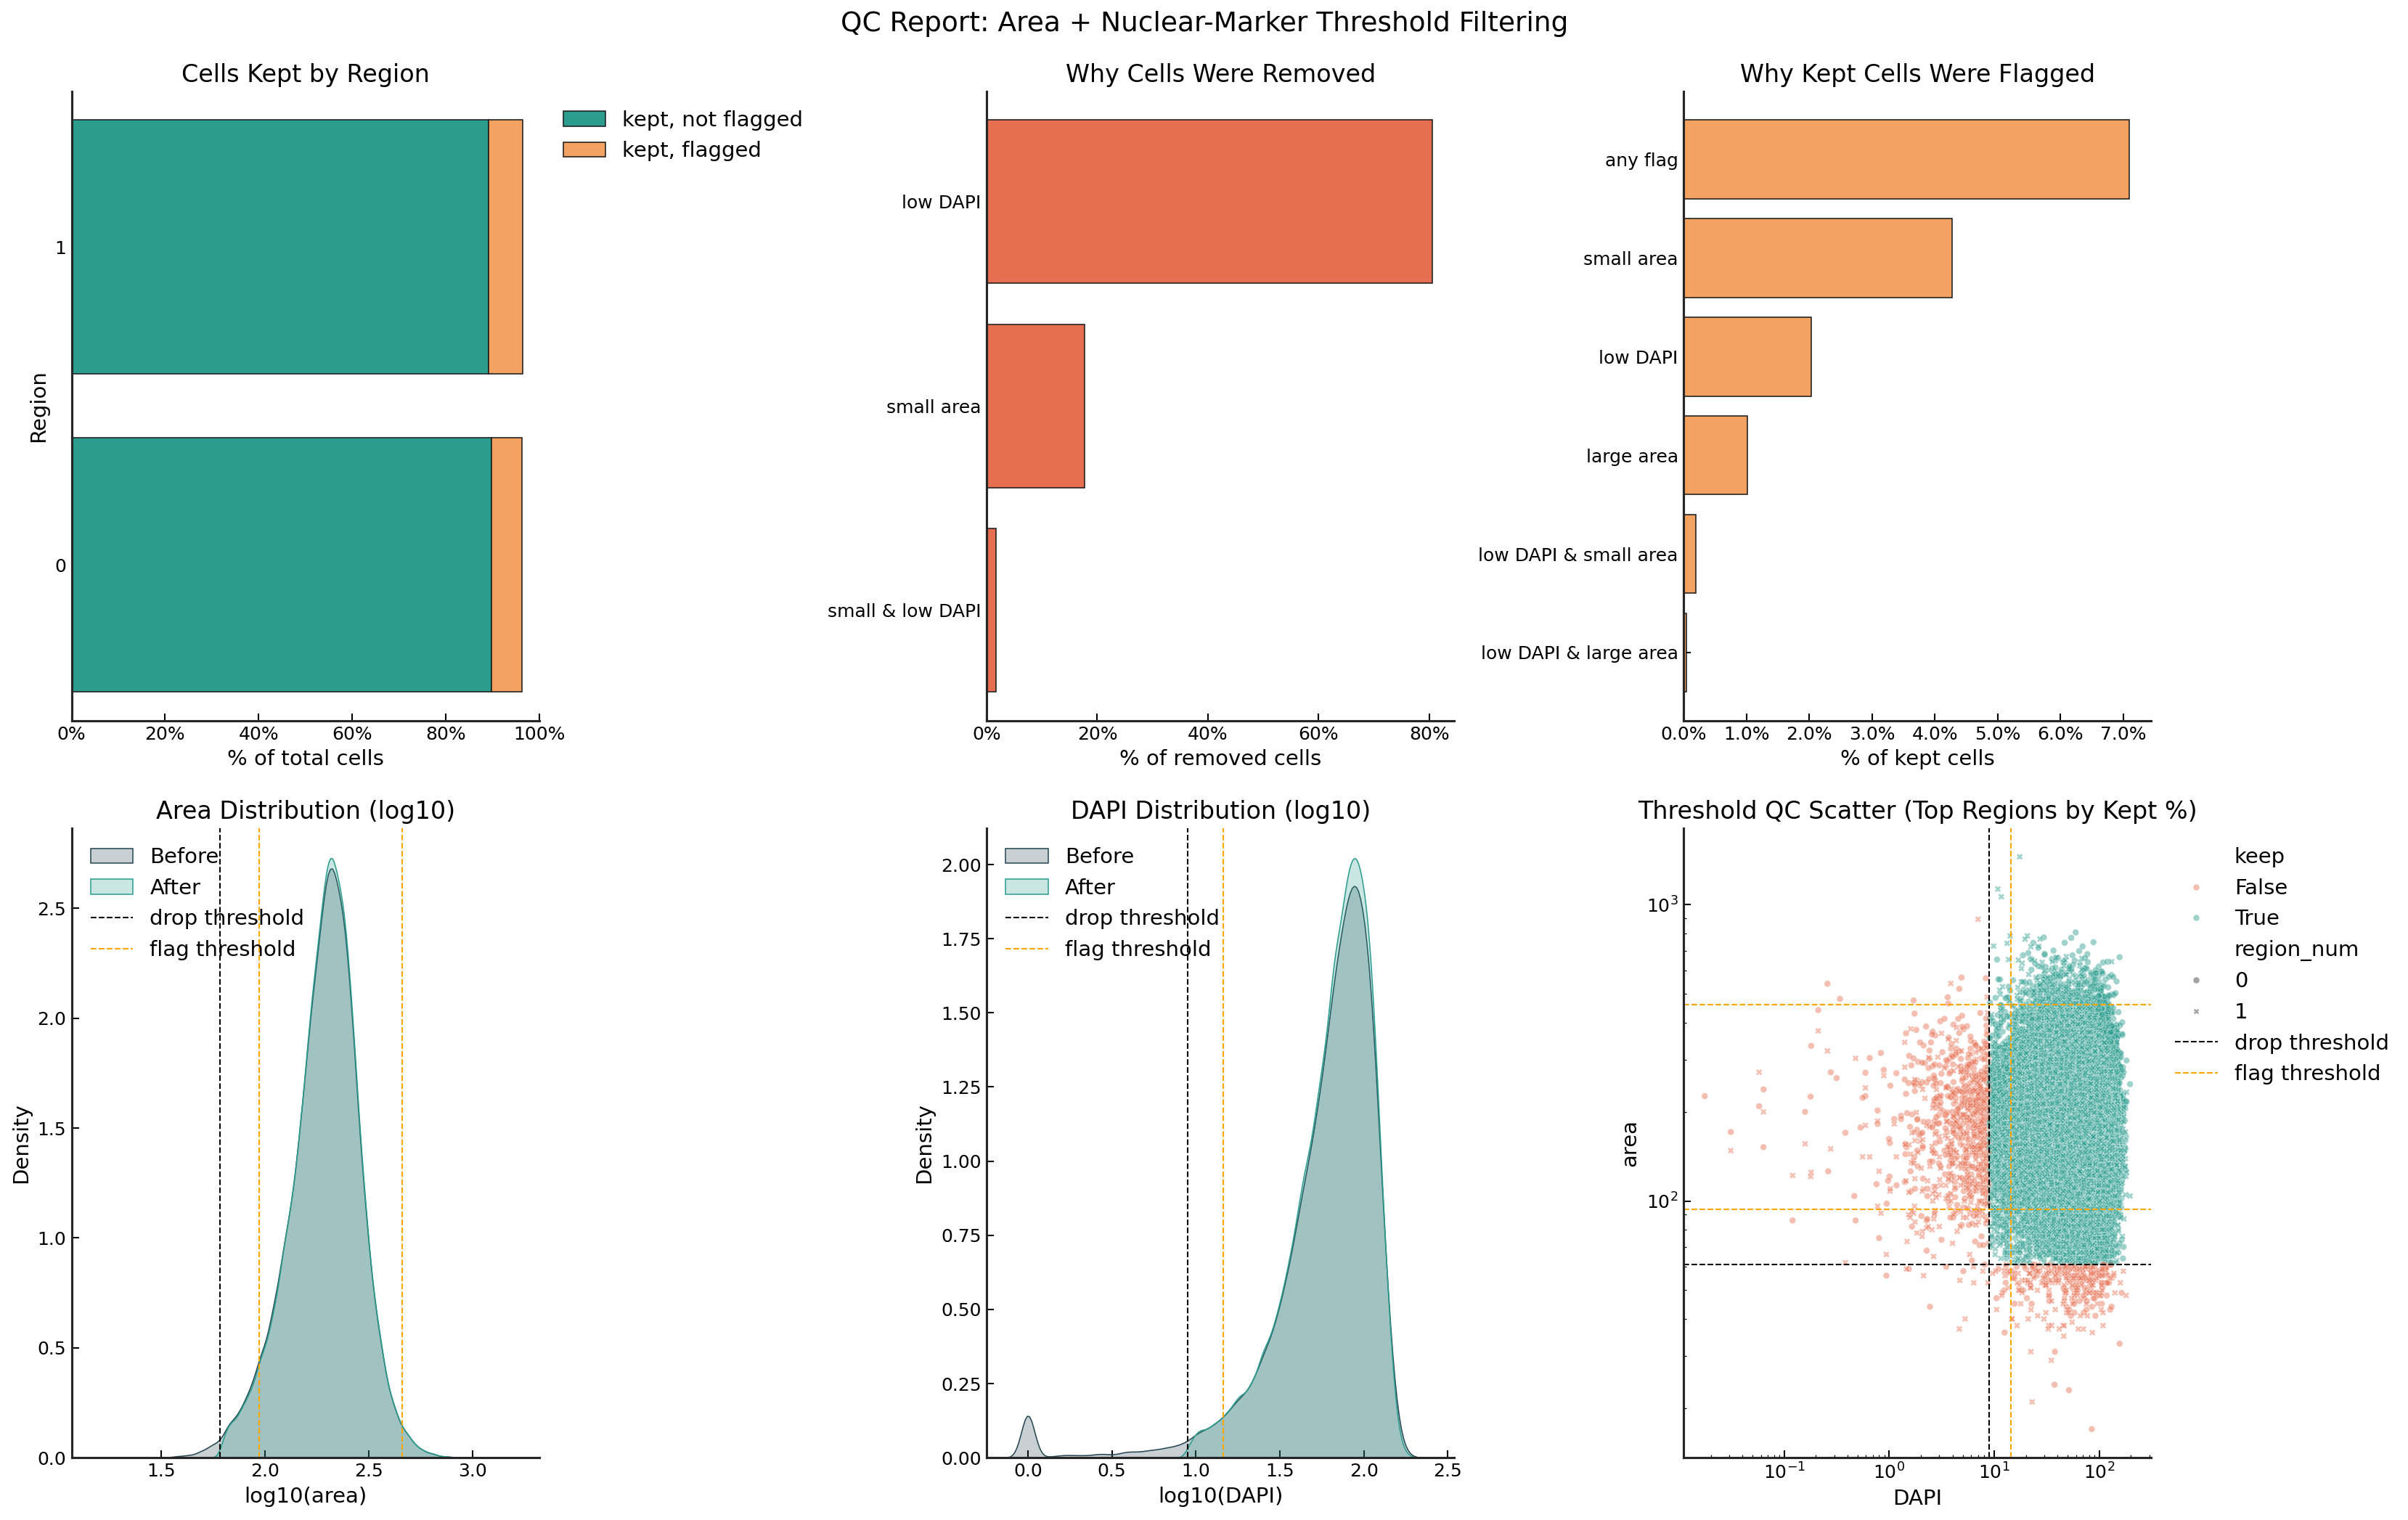

In [8]:
# If necessary filter the dataframe to remove too small objects or cells without a nucleus.
# Identify the lowest 1% for cell size and nuclear marker intensity to get a better idea of potential segmentation artifacts.
df_filt, qc_dashboard_fig, filter_summary = sp.pp.filter_data(
    df_seg, 
    nuc_thres=nuc_stain_cutoff, # remove cells with DAPI intensity below threshold
    size_thres=area_cutoff, # remove cells with area below threshold
    nuc_marker="DAPI", # name of nuclear marker
    cell_size = "area", # name of cell size column
    region_column = "region_num", # group QC dashboard panel A by region
    log_scale=False, # log scale for size
    nuc_flag_thres=nuc_flag_cutoff, # flag cells between the removal and flagging DAPI thresholds
    size_flag_thres=area_flag_cutoff, # flag cells between the removal and flagging low area thresholds
    size_upper_flag_thres=area_upper_flag_cutoff, # flag the cells with size above this threshold
    qc_dashboard=True, return_summary=True); # (df_filt, qc_dashboard_fig, filter_summary)

In [9]:
filter_summary

,region_num,n_total,n_kept,n_removed,pct_kept,removed: low DAPI,removed: small & low DAPI,removed: small area,pct_flagged,flagged: low DAPI,flagged: small area,flagged: large area,flagged: any flag
0,0,27997,26971,1026,96.335322,886,10,130,6.788773,583,994,299,1831
1,1,23054,22218,836,96.373731,613,23,200,7.457917,420,1108,202,1657


## Normalize data

`sp.pp.format` supports four normalization methods, chosen with `method=`:

- **`zscore`** (default) -- standard per-marker z-score across cells: `(x - mean) / std`. The right default for most panels.
- **`double_zscore`** -- z-scores columns (markers), then additionally z-scores the resulting rows (cells). Use this if cells still show large staining-intensity differences after a per-marker z-score, e.g. from uneven tissue thickness.
- **`MinMax`** -- rescales each marker to `[0, 1]`. Preserves the original distribution shape (no assumption of normality) but is sensitive to outliers, since a single extreme value stretches the whole scale.
- **`ArcSin`** -- an inverse hyperbolic sine transform, `arcsinh(x / ArcSin_cofactor)`. Common for cytometry-style data with a long right tail; compresses high intensities without the hard floor a log transform has at zero.

**Why per region, in a loop:** `format` normalizes one DataFrame at a time and has no built-in notion of "region" -- z-scoring is a per-marker statistic (mean/std) computed over whatever rows you give it, so if regions were normalized together, a systematically brighter region (e.g. more autofluorescence, a thicker section) would bias every cell's z-score, not just that region's. Looping over `unique_region` and concatenating keeps each region's normalization independent.

**Why `DAPI` ends up in `list_keep`:** any column in `list_keep` is treated as metadata and excluded from normalization, so it lands in `adata.obs` (not `adata.X`) once `make_anndata` splits the table -- i.e. it will *not* be used for clustering. That's deliberate here: DAPI marks nuclei for segmentation QC, not a cell-type marker, so it isn't a clustering feature. If your panel needs DAPI itself as a clustering feature, move it out of `list_keep`.

In [10]:
# Normalize data with one of the four available methods (zscore as default)
df_filt.columns

Index(['y', 'x', 'area', 'eccentricity', 'perimeter', 'convex_area',
       'axis_major_length', 'axis_minor_length', 'DAPI', 'FoxP3', 'HLA-DR',
       'CD103', 'CHGA', 'EGFR', 'CD206', 'GFAP', 'PD-1', 'BCL2', 'panCK',
       'CD45RO', 'CD11b', 'CD56', 'CD163', 'CD21', 'CD8', 'S100', 'Vimentin',
       'PDGFRb', 'CCR7', 'CD57', 'CD34', 'Synaptophysin', 'CD31', 'CXCR5',
       'CD3', 'CD38', 'LAG3', 'CD25', 'CD16', 'IL-10', 'Ki67', 'CLEC9A', 'p53',
       'CD69', 'CD11c', 'CD68', 'Ox40', 'aSMA', 'CD20', 'CD4', 'MUC-1',
       'Podoplanin', 'CD45RA', 'CD15', 'betaCatenin', 'PAX5', 'MCT', 'FAP',
       'CD138', 'Tbet', 'GranzymeB', 'IDO-1', 'CD45', 'CollagenIV', 'PD-L1',
       'Arginase-1', 'GATA3', 'region_num', 'unique_region', 'condition',
       'unique_cell_id', 'label', 'qc_flag_low_dapi', 'qc_flag_low_size',
       'qc_flag_large_size', 'qc_flag_any'],
      dtype='object')

In [11]:
full_marker_list = ['FoxP3', 'HLA-DR',
       'CD103', 'CHGA', 'EGFR', 'CD206', 'GFAP', 'PD-1', 'BCL2', 'panCK',
       'CD45RO', 'CD11b', 'CD56', 'CD163', 'CD21', 'CD8', 'S100', 'Vimentin',
       'PDGFRb', 'CCR7', 'CD57', 'CD34', 'Synaptophysin', 'CD31', 'CXCR5',
       'CD3', 'CD38', 'LAG3', 'CD25', 'CD16', 'IL-10', 'Ki67', 'CLEC9A', 'p53',
       'CD69', 'CD11c', 'CD68', 'Ox40', 'aSMA', 'CD20', 'CD4', 'MUC-1',
       'Podoplanin', 'CD45RA', 'CD15', 'betaCatenin', 'PAX5', 'MCT', 'FAP',
       'CD138', 'Tbet', 'GranzymeB', 'IDO-1', 'CD45', 'CollagenIV', 'PD-L1',
       'Arginase-1', 'GATA3']

In [12]:
# normalize data per region:
dfz = pd.DataFrame()

for region in df_filt.unique_region.unique():
    df_reg = df_filt[df_filt.unique_region == region]
    df_reg_norm = sp.pp.format(
        data=df_reg,
        markers=full_marker_list, # all markers to normalize.
        # DAPI is usually omitted, as it won't be used for clustering -- it (and every
        # other non-marker column) passes through unchanged automatically.
        method="zscore") # choose from "zscore", "double_zscore", "MinMax", "ArcSin"
    dfz = pd.concat([dfz, df_reg_norm], axis=0)

dfz.shape

(49189, 76)

## Remove noisy cells
This section is used to remove noisy cells. This is very important to ensure proper identification of the cells via clustering.

reg001


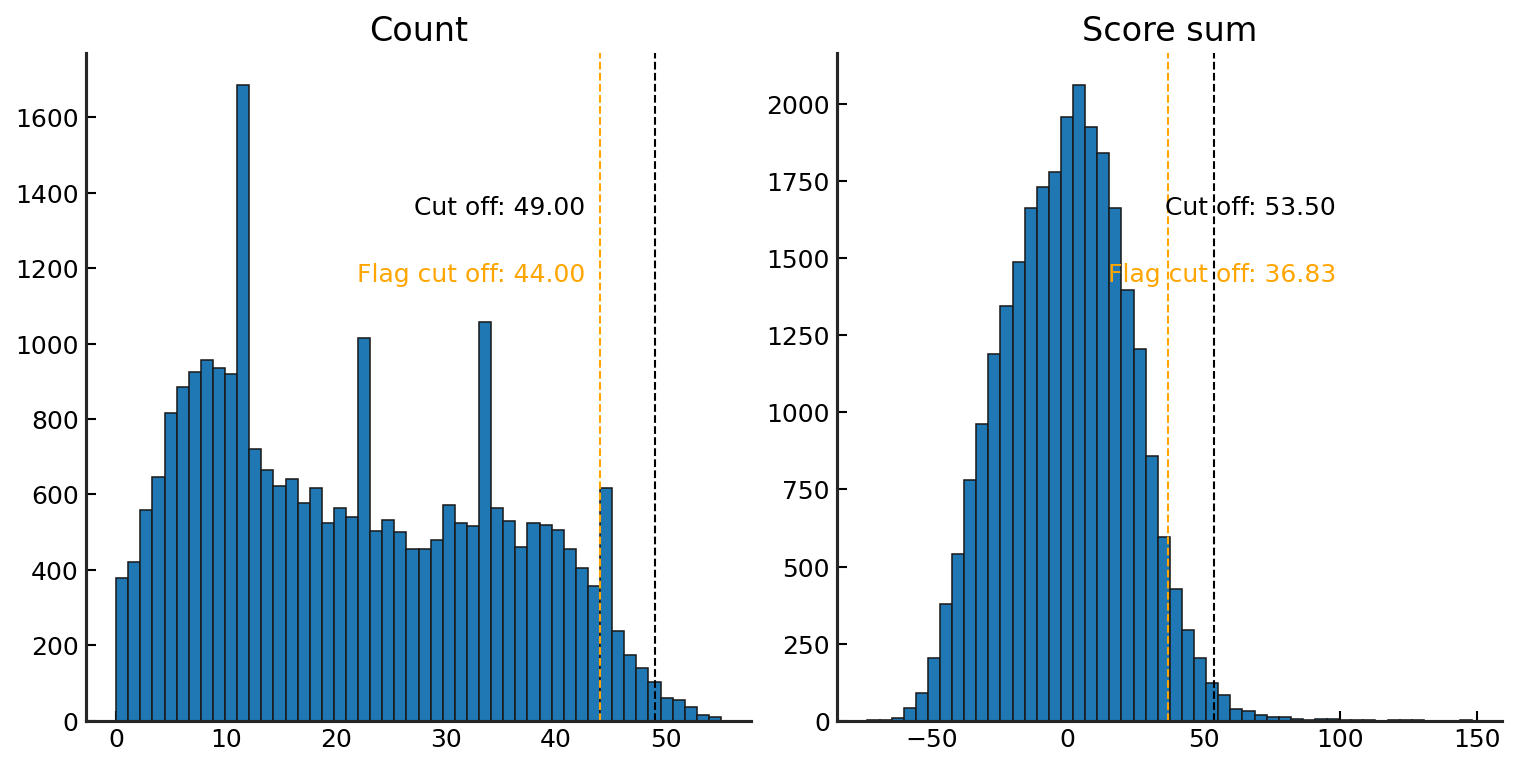

reg002


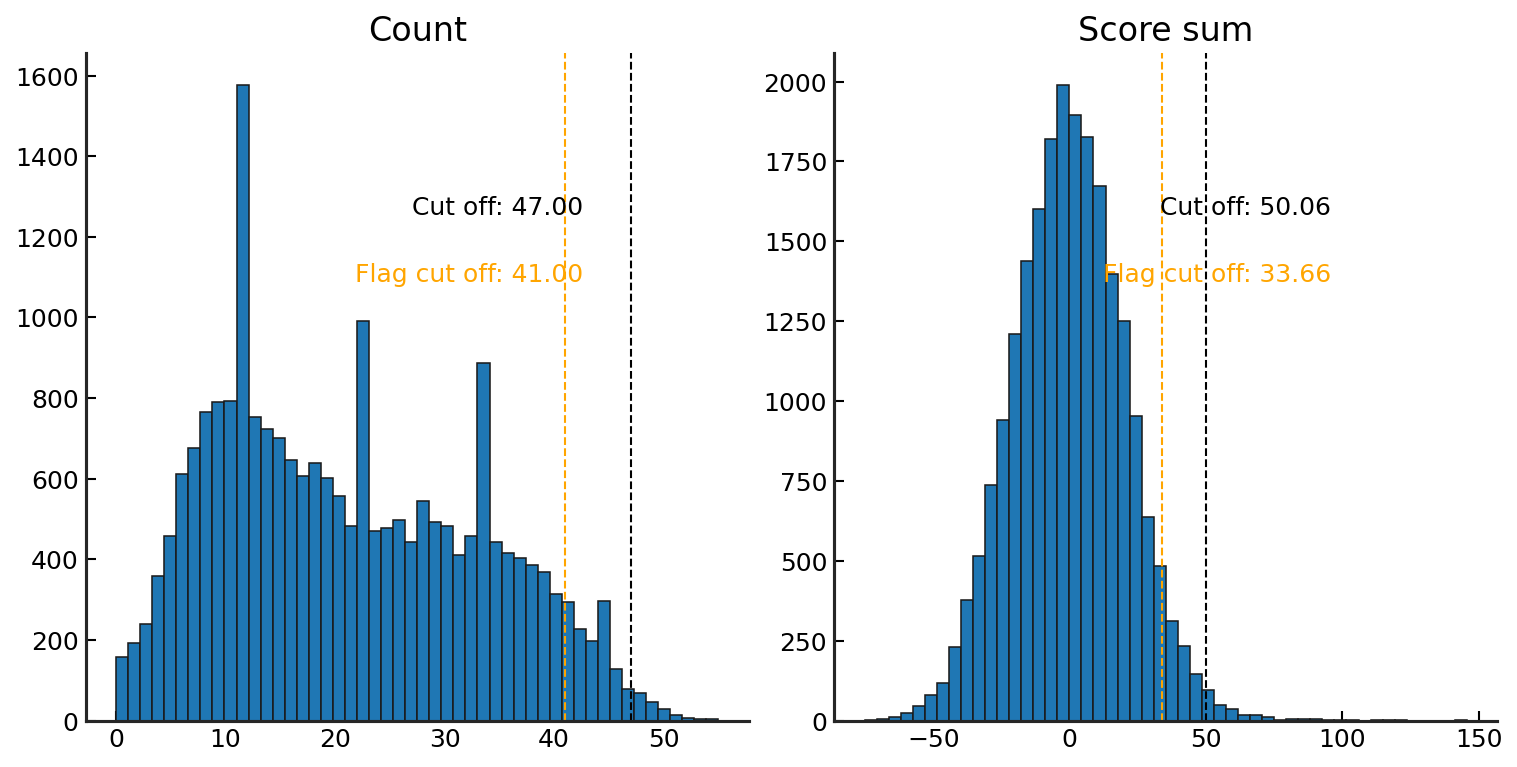

{'reg001': {'count_cut_off': 49.0,
  'score_sum_cut_off': 53.503595246653134,
  'count_flag_cut_off': 44.0,
  'score_sum_flag_cut_off': 36.833218239457445},
 'reg002': {'count_cut_off': 47.0,
  'score_sum_cut_off': 50.06406530783307,
  'count_flag_cut_off': 41.0,
  'score_sum_flag_cut_off': 33.65503302256279}}

In [13]:
# This function helps determine appropriate thresholds for each region
region_thresholds = {}

for region in dfz.unique_region.unique():
    print(region)

    df_reg = dfz[dfz.unique_region == region]

    # sp.pp.marker_score_thres computes the thresholds remove_noise needs below, and (with
    # qc_dashboard=True, the default) also returns a diagnostic histogram figure. We
    # display and close each region's figure explicitly, so the loop below doesn't leave
    # figures piling up in memory across regions.
    region_threshold, score_QC_fig = sp.pp.marker_score_thres(
        dfz=df_reg,                    # this region's normalized data
        marker_list=full_marker_list,  # the marker columns to score
        cut_off=0.01,                  # top 1% of cells -- dropped
        count_bin=50,                  # number of bins for the Count histogram
        score_sum_bin=50,              # number of bins for the Score-sum histogram
        figsize=(10, 5),               # figure size in inches (width, height)
        qc_dashboard=True,             # also build+return the 2-panel histogram figure
        flag_cut_off=0.05,             # top 5% of cells -- flagged, not dropped
        positive_thres=0,              # threshold for 'positive expression'. default 0 for zscore;
        # set to e.g. 0.5 when using MinMax normalization, or find a suitable threshold
        # for other data distributions.
        style=None,                    # None = use the notebook's active style (presentation())
    )
    region_thresholds[region] = region_threshold
    display(score_QC_fig)
    plt.close(score_QC_fig)

region_thresholds


`marker_score_thres` above calculates, per region, how many markers each cell scores as positive for (`Count`) against its total normalized signal (`Score sum`). "Noisy" cells here means cells that are high across *many* markers at once -- a biologically implausible pattern that usually indicates a segmentation artifact (e.g. two cells merged into one mask) or debris, rather than a real, specific cell type.

`region_thresholds`: `cut_off=0.01`/`flag_cut_off=0.05` are quantiles of each region's own `Count`/`Score sum` distribution. `marker_score_thres` returns `thresholds, fig`, with `thresholds` a `{"count_cut_off", "score_sum_cut_off", "count_flag_cut_off", "score_sum_flag_cut_off"}` dict. The dashed lines on the plots are for sanity-checking those quantiles against the actual distribution shape. If a region's distribution looks bimodal or otherwise odd, re-run with a different `cut_off`/`flag_cut_off`.

In [14]:
# Once the thresholds in the plots above look reasonable, remove the top X% of all cells that are highly expressive for all antibodies,
# and flag (not drop) the next band out to Y%, using the thresholds computed above.
df_nn = pd.DataFrame()

for region in dfz.unique_region.unique():
    df_reg = dfz[dfz.unique_region == region]
    thres = region_thresholds[region]
    df_reg_nn, cc = sp.pp.remove_noise(
        df=df_reg,
        marker_list=full_marker_list,                           # same marker list as above
        count_thres=thres["count_cut_off"],                     # number obtained from the function above
        score_sum_thres=thres["score_sum_cut_off"],             # number obtained from the function above
        count_flag_thres=thres["count_flag_cut_off"],           # looser count threshold -- flagged, not dropped
        score_sum_flag_thres=thres["score_sum_flag_cut_off"],   # looser score-sum threshold -- flagged, not dropped
        positive_thres=0,                                       # must match the marker_score_thres call above
    )
    print(df_reg_nn.shape)
    df_nn = pd.concat([df_nn,df_reg_nn], axis = 0)
df_nn.shape

1.5% cells are removed.
qc_flag_noise: 5.29% of kept cells flagged
(26578, 77)
1.5% cells are removed.
qc_flag_noise: 5.62% of kept cells flagged
(21879, 77)


(48457, 77)

In [15]:
#Save the df as a backup. We strongly recommend the Anndata format for further analysis!
df_nn.to_csv(output_dir + "df_nn_demo.csv")

In [16]:
# inspect which markers work, and drop the ones that did not work from the clustering step
# generate an anndata object for compatibility with the downstream clustering step
adata = sp.hf.make_anndata(
    df_nn = df_nn,
    marker_list = full_marker_list, # markers will be part of adata.X; all remaining non-marker features go into adata.obs
    nonFuncAb_list = [] # Remove the antibodies that are not working from the clustering step
)
adata

AnnData object with n_obs × n_vars = 48457 × 58
    obs: 'y', 'x', 'area', 'eccentricity', 'perimeter', 'convex_area', 'axis_major_length', 'axis_minor_length', 'DAPI', 'region_num', 'unique_region', 'condition', 'unique_cell_id', 'label', 'qc_flag_low_dapi', 'qc_flag_low_size', 'qc_flag_large_size', 'qc_flag_any', 'qc_flag_noise'
    obsm: 'spatial'

`make_anndata` now sets `adata.obs_names` automatically from the `unique_cell_id` column added by `read_segdf` (unique across regions, unlike the raw per-region cell label/id), so cells stay traceable back to their segmentation mask after filtering and multi-region concatenation. `label` and `unique_region` remain in `adata.obs` for that lookup — see `spacec.hf.hf_attach_masks`/`spacec.hf.hf_load_masks` if you want to attach the raw masks themselves to the AnnData for per-cell pixel lookup.

In [17]:
# Save the annotated AnnData object to a file. Make sure 04_clustering.ipynb reads
# from this same path when you continue the pipeline there.
adata.write_h5ad(output_dir + 'adata_nn_demo_tonsil.h5ad')

## Attach segmentation masks for per-cell pixel lookup (Optional)

The note above mentioned `sp.hf.hf_attach_masks`/`sp.hf.hf_load_masks` -- here's what that looks like in practice. Loading each region's raw label mask and attaching it to `adata.uns["masks"]` lets any `adata.obs` row be traced back to its exact pixels via `obs["unique_region"]` + `obs["label"]`, without reloading segmentation output from disk.

This attaches masks to the in-memory `adata` only (not re-saved into `adata_nn_demo_tonsil.h5ad` above), since a mask is a full-resolution label image per region -- attach and save your own copy below if you want them to persist.

In [18]:
# One raw label mask per region, written by cell_segmentation(save_mask=True) in 02_cell_segmentation
region_to_output_fname = {"reg001": "tonsil1", "reg002": "tonsil2"}

masks = sp.hf.hf_load_masks(
    {region: output_dir + f'{output_fname}_mask.tif' for region, output_fname in region_to_output_fname.items()}
)

sp.hf.hf_attach_masks(adata, masks)
adata.uns["masks"].keys()

dict_keys(['reg001', 'reg002'])

`sp.pl.expression_on_masks` recolors a region's mask by a marker's per-cell expression (rather than by cell type/cluster, which `sp.pl.plot_masks` is built for), showing the actual segmented cell shape behind each measurement in `adata`, not just a centroid dot like `coordinates_on_image` further down. It reads the masks attached above and matches them to `adata` by `obs["unique_region"]` + `obs["label"]`. Cells dropped by `filter_data`/`remove_noise` upstream are absent from `adata.obs["label"]`, so their pixels fall back to the background color here -- a direct look at what filtering removed.

`marker=` accepts several markers at once, and any numeric `adata.obs` column (e.g. `"area"`) also works. Leaving out `subset=` plots every region that has a mask, on one shared color scale per marker so the panels stay comparable.

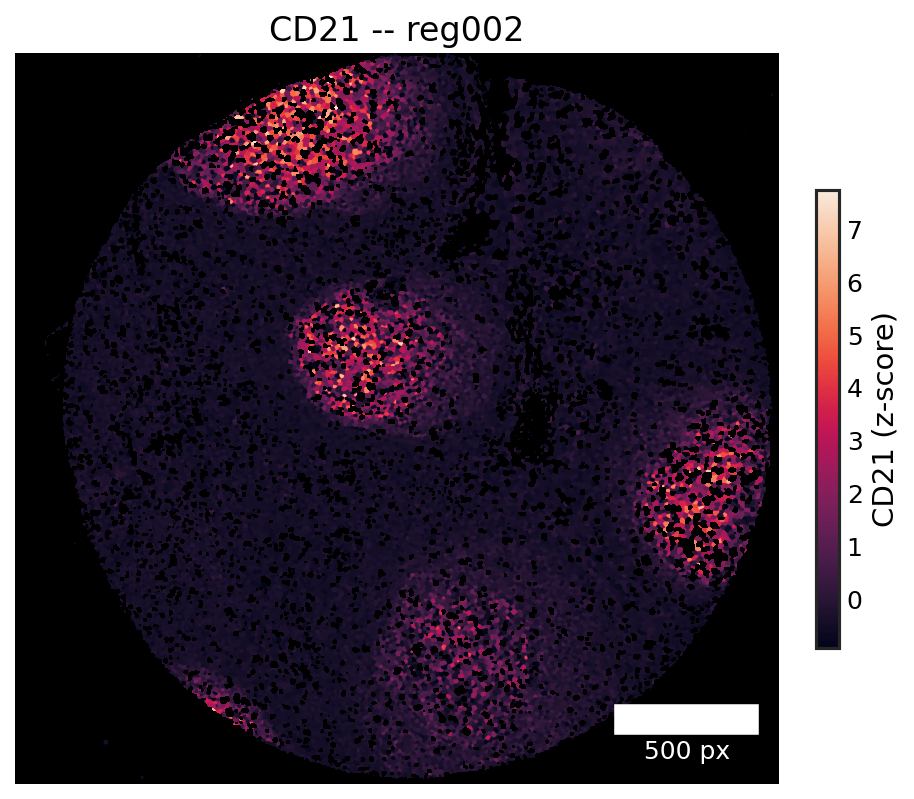

In [19]:
sp.pl.expression_on_masks(
    adata,
    marker = "CD21", # a marker in adata.var_names, or a numeric adata.obs column
    subset = "reg002", # omit to plot every region that has a mask
    cmap = "rocket",
    background = "black", # background pixels + cells removed by filtering
    colorbar_label = "CD21 (z-score)",
    figsize = 6,
)

# Several markers at once, one panel each, shared color scale per marker:
# sp.pl.expression_on_masks(adata, marker=["CD21", "CD8"], subset="reg002")